# Static Versus Greedy Driver-Set Construction

This notebook collects the results for the static-versus-greedy comparison section. It is meant to make it easy to:

- quantify how much seeded-greedy extension improves scalar control energy,
- compare static and greedy constructions for the degree- and cycle-based rankings used in the paper,
- test whether conditional extension changes control geometry as well as energy,
- summarize how greedy extension alters the hardest control directions.

The main focus here is on `degree_strength` and `cycle_participation`, because those are the methods carried through the manuscript narrative.


In [2]:
from pathlib import Path
import os
os.environ.setdefault('MPLCONFIGDIR', '/private/tmp/matplotlib')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

REPO_ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
RESULTS_DIR = REPO_ROOT / 'results'
FIGURES_DIR = REPO_ROOT / 'figures' / 'section_static_vs_greedy'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(context='talk', style='whitegrid')
palette = {
    'degree_strength': '#cc7a29',
    'cycle_participation': '#4c72b0',
}
label_map = {
    'degree_strength': 'Degree-seeded',
    'cycle_participation': 'Topology-seeded',
}
scale_palette = {68: '#6a51a3', 114: '#3182bd', 219: '#31a354'}


In [3]:
greedy = pd.read_csv(RESULTS_DIR / 'primary' / 'greedy_comparison.csv')
geometry = pd.read_csv(RESULTS_DIR / 'primary' / 'geometry_metrics.csv')
overlap = pd.read_csv(RESULTS_DIR / 'primary' / 'eigenspace_overlap.csv')

methods = ['degree_strength', 'cycle_participation']
greedy = greedy[greedy['method'].isin(methods)].copy()
geometry = geometry[geometry['method'].isin(methods)].copy()

greedy['complementarity_gain_log10'] = -greedy['greedy_minus_static_log10']
greedy.head()


,subject_id,scale,k,method,static_log10_average_energy,greedy_log10_average_energy,greedy_minus_static_log10,complementarity_gain_log10
0,sub-000,68,1,degree_strength,6.800841,6.800841,0.000000,-0.000000
2,sub-000,68,1,cycle_participation,6.801388,6.801388,0.000000,-0.000000
3,sub-000,68,2,degree_strength,6.776458,6.775252,-0.001206,0.001206
5,sub-000,68,2,cycle_participation,6.775227,6.775227,0.000000,-0.000000
6,sub-000,68,3,degree_strength,6.758232,6.751083,-0.007149,0.007149


## Scalar energy summaries

The core scalar quantity here is

- `greedy_minus_static_log10 = log10(E_greedy) - log10(E_static)`

so negative values mean the seeded-greedy extension found a lower-energy driver set than the static top-`k` ranking.


In [4]:
scalar_summary = (
    greedy.groupby(['scale', 'k', 'method'], as_index=False)
    .agg(
        n_subjects=('subject_id', 'nunique'),
        mean_static_log10=('static_log10_average_energy', 'mean'),
        sem_static_log10=('static_log10_average_energy', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_greedy_log10=('greedy_log10_average_energy', 'mean'),
        sem_greedy_log10=('greedy_log10_average_energy', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_greedy_minus_static=('greedy_minus_static_log10', 'mean'),
        sem_greedy_minus_static=('greedy_minus_static_log10', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_complementarity_gain=('complementarity_gain_log10', 'mean'),
        sem_complementarity_gain=('complementarity_gain_log10', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    )
)
scalar_summary


,scale,k,method,n_subjects,mean_static_log10,sem_static_log10,mean_greedy_log10,sem_greedy_log10,mean_greedy_minus_static,sem_greedy_minus_static,mean_complementarity_gain,sem_complementarity_gain
0,68,1,cycle_participation,70,6.803877,0.000288,6.803877,0.000288,0.000000,0.000000,0.000000,0.000000
1,68,1,degree_strength,70,6.803082,0.000214,6.803082,0.000214,0.000000,0.000000,0.000000,0.000000
2,68,2,cycle_participation,70,6.782724,0.000417,6.779836,0.000326,-0.002888,0.000263,0.002888,0.000263
3,68,2,degree_strength,70,6.782871,0.000406,6.779785,0.000351,-0.003086,0.000260,0.003086,0.000260
4,68,3,cycle_participation,70,6.762189,0.000522,6.757148,0.000433,-0.005041,0.000378,0.005041,0.000378
5,68,3,degree_strength,70,6.762839,0.000492,6.757270,0.000476,-0.005569,0.000250,0.005569,0.000250
6,68,5,cycle_participation,70,6.721548,0.000738,6.711858,0.000630,-0.009690,0.000559,0.009690,0.000559
7,68,5,degree_strength,70,6.723851,0.000881,6.712064,0.000693,-0.011787,0.000459,0.011787,0.000459
8,114,1,cycle_participation,70,7.040476,0.000197,7.040476,0.000197,0.000000,0.000000,0.000000,0.000000
9,114,1,degree_strength,70,7.039422,0.000119,7.039422,0.000119,0.000000,0.000000,0.000000,0.000000


In [5]:
scalar_avgk = (
    greedy.groupby(['subject_id', 'scale', 'method'], as_index=False)
    .agg(
        mean_static_log10=('static_log10_average_energy', 'mean'),
        mean_greedy_log10=('greedy_log10_average_energy', 'mean'),
        mean_greedy_minus_static=('greedy_minus_static_log10', 'mean'),
        mean_complementarity_gain=('complementarity_gain_log10', 'mean'),
    )
)
scalar_avgk.groupby(['scale', 'method'])[['mean_static_log10', 'mean_greedy_log10', 'mean_greedy_minus_static']].mean().round(6)


mean_static_log10  mean_greedy_log10  \
scale method                                                      
68    cycle_participation           6.767585           6.763180   
      degree_strength               6.768161           6.763050   
114   cycle_participation           7.019389           7.016968   
      degree_strength               7.018419           7.016249   
219   cycle_participation           7.320842           7.319386   
      degree_strength               7.319745           7.318793   

                           mean_greedy_minus_static  
scale method                                         
68    cycle_participation                 -0.004405  
      degree_strength                     -0.005111  
114   cycle_participation                 -0.002420  
      degree_strength                     -0.002171  
219   cycle_participation                 -0.001456  
      degree_strength                     -0.000953

In [6]:
scalar_tests = []
for (scale, method), subset in greedy.groupby(['scale', 'method']):
    stat, p = wilcoxon(subset['greedy_minus_static_log10'])
    scalar_tests.append({
        'scale': scale,
        'method': method,
        'mean_greedy_minus_static': subset['greedy_minus_static_log10'].mean(),
        'statistic': stat,
        'p_value': p,
    })
scalar_tests = pd.DataFrame(scalar_tests).sort_values(['scale', 'method']).reset_index(drop=True)
scalar_tests['p_value_holm'] = multipletests(scalar_tests['p_value'], method='holm')[1]
scalar_tests['reject_holm'] = scalar_tests['p_value_holm'] < 0.05
scalar_tests


,scale,method,mean_greedy_minus_static,statistic,p_value,p_value_holm,reject_holm
0,68,cycle_participation,-0.004405,0.0,1.491793e-35,3.068545e-35,True
1,68,degree_strength,-0.005111,0.0,4.808741e-36,2.404371e-35,True
2,114,cycle_participation,-0.002420,0.0,1.022848e-35,3.068545e-35,True
3,114,degree_strength,-0.002171,0.0,4.808741e-36,2.404371e-35,True
4,219,cycle_participation,-0.001456,0.0,3.297226e-36,1.978336e-35,True
5,219,degree_strength,-0.000953,0.0,1.491793e-35,3.068545e-35,True


## Figure: scalar trajectories and complementarity gain


PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_static_vs_greedy/static_vs_greedy_scalar_summary.svg')

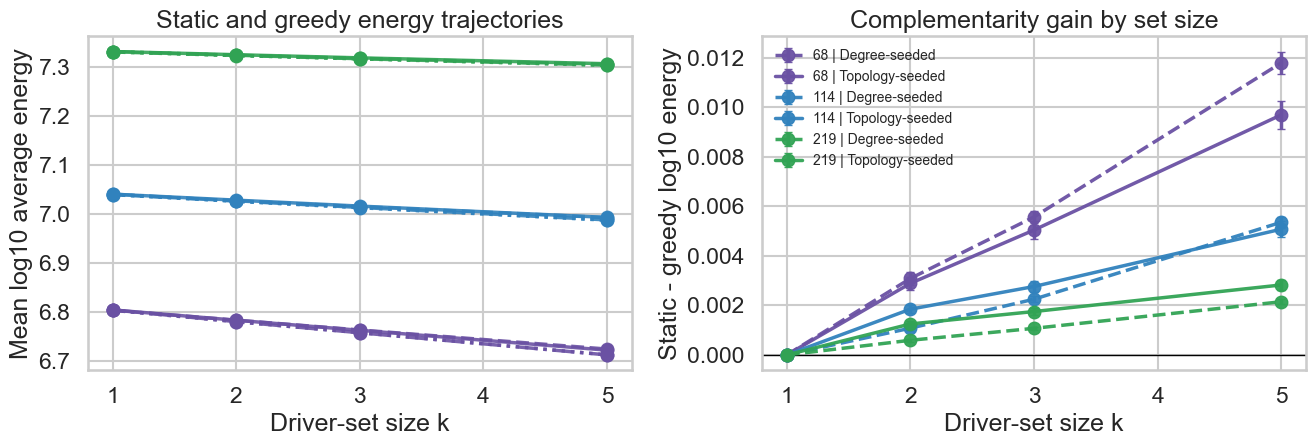

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

for scale in sorted(scalar_summary['scale'].unique()):
    for method in methods:
        subset = scalar_summary[(scalar_summary['scale'] == scale) & (scalar_summary['method'] == method)].sort_values('k')
        axes[0].plot(
            subset['k'],
            subset['mean_static_log10'],
            marker='o',
            linewidth=2.5,
            color=scale_palette[scale],
            linestyle='--' if method == 'degree_strength' else '-',
            alpha=0.9,
            label=f"{scale} | {label_map[method]}" if method == 'degree_strength' else None,
        )
        axes[0].plot(
            subset['k'],
            subset['mean_greedy_log10'],
            marker='o',
            linewidth=2.5,
            color=scale_palette[scale],
            linestyle=':' if method == 'degree_strength' else '-.',
            alpha=0.9,
        )

for scale in sorted(scalar_summary['scale'].unique()):
    for method in methods:
        subset = scalar_summary[(scalar_summary['scale'] == scale) & (scalar_summary['method'] == method)].sort_values('k')
        axes[1].errorbar(
            subset['k'],
            subset['mean_complementarity_gain'],
            yerr=subset['sem_complementarity_gain'],
            marker='o',
            linewidth=2.5,
            capsize=3,
            color=scale_palette[scale],
            linestyle='--' if method == 'degree_strength' else '-',
            alpha=0.95,
            label=f"{scale} | {label_map[method]}",
        )

axes[0].set_xlabel('Driver-set size k')
axes[0].set_ylabel('Mean log10 average energy')
axes[0].set_title('Static and greedy energy trajectories')
# axes[0].text(0.02, 0.03, 'solid/dash styles separate method; second line style per color is greedy vs static', transform=axes[0].transAxes, fontsize=9)
axes[1].set_xlabel('Driver-set size k')
axes[1].set_ylabel('Static - greedy log10 energy')
axes[1].set_title('Complementarity gain by set size')
axes[1].axhline(0, color='black', linewidth=1)
axes[1].legend(frameon=False, fontsize=10, title='')
fig.tight_layout()
out = FIGURES_DIR / 'static_vs_greedy_scalar_summary.svg'
fig.savefig(out, bbox_inches='tight')
out


## Geometry summaries

Here we pivot the saved geometry metrics so that each subject / scale / `k` / method has both a static and greedy row. We then summarize the within-method geometric change induced by greedy extension.


In [8]:
geometry_wide = geometry.pivot_table(
    index=['subject_id', 'scale', 'k', 'method'],
    columns='selection_strategy',
    values=['log10_average_energy', 'effective_rank', 'participation_ratio', 'log10_condition_number'],
)
geometry_wide.columns = ['_'.join(col) for col in geometry_wide.columns]
geometry_wide = geometry_wide.reset_index()
geometry_wide['delta_log10_average_energy'] = geometry_wide['log10_average_energy_greedy'] - geometry_wide['log10_average_energy_static']
geometry_wide['delta_effective_rank'] = geometry_wide['effective_rank_greedy'] - geometry_wide['effective_rank_static']
geometry_wide['delta_participation_ratio'] = geometry_wide['participation_ratio_greedy'] - geometry_wide['participation_ratio_static']
geometry_wide['delta_log10_condition_number'] = geometry_wide['log10_condition_number_greedy'] - geometry_wide['log10_condition_number_static']
geometry_wide.head()


,subject_id,scale,k,method,effective_rank_greedy,effective_rank_static,log10_average_energy_greedy,log10_average_energy_static,log10_condition_number_greedy,log10_condition_number_static,participation_ratio_greedy,participation_ratio_static,delta_log10_average_energy,delta_effective_rank,delta_participation_ratio,delta_log10_condition_number
0,sub-000,68,1,cycle_participation,1.819955,1.819955,6.801388,6.801388,4.511342,4.511342,1.512962,1.512962,0.000000,0.000000,0.000000,0.000000
1,sub-000,68,1,degree_strength,1.675523,1.675523,6.800841,6.800841,4.946461,4.946461,1.397570,1.397570,0.000000,0.000000,0.000000,0.000000
2,sub-000,68,2,cycle_participation,2.684085,2.684085,6.775227,6.775227,4.941877,4.941877,2.137513,2.137513,0.000000,0.000000,0.000000,0.000000
3,sub-000,68,2,degree_strength,2.507454,2.483251,6.775252,6.776458,5.061144,5.081490,1.936122,1.919455,-0.001206,0.024202,0.016667,-0.020346
4,sub-000,68,3,cycle_participation,3.533074,3.448001,6.750357,6.752647,4.996170,5.035485,2.719026,2.636876,-0.002290,0.085073,0.082150,-0.039315


In [9]:
geometry_summary = (
    geometry_wide.groupby(['scale', 'k', 'method'], as_index=False)
    .agg(
        mean_delta_effective_rank=('delta_effective_rank', 'mean'),
        sem_delta_effective_rank=('delta_effective_rank', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_delta_participation_ratio=('delta_participation_ratio', 'mean'),
        sem_delta_participation_ratio=('delta_participation_ratio', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_delta_log10_condition_number=('delta_log10_condition_number', 'mean'),
        sem_delta_log10_condition_number=('delta_log10_condition_number', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    )
)
geometry_summary


,scale,k,method,mean_delta_effective_rank,sem_delta_effective_rank,mean_delta_participation_ratio,sem_delta_participation_ratio,mean_delta_log10_condition_number,sem_delta_log10_condition_number
0,68,1,cycle_participation,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,68,1,degree_strength,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,68,2,cycle_participation,0.259225,0.035410,0.197052,0.036986,0.009197,0.029787
3,68,2,degree_strength,0.346422,0.033054,0.268269,0.026902,-0.165044,0.012627
4,68,3,cycle_participation,0.373514,0.058365,0.298031,0.070533,-0.007738,0.031829
5,68,3,degree_strength,0.720196,0.037618,0.582436,0.034753,-0.232808,0.011058
6,68,5,cycle_participation,0.577472,0.116964,0.528509,0.160740,-0.050019,0.038550
7,68,5,degree_strength,1.600389,0.052969,1.315382,0.056734,-0.316161,0.011096
8,114,1,cycle_participation,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,114,1,degree_strength,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [10]:
geometry_tests_zero = []
for metric in ['delta_effective_rank', 'delta_participation_ratio', 'delta_log10_condition_number']:
    for (scale, method), subset in geometry_wide.groupby(['scale', 'method']):
        stat, p = wilcoxon(subset[metric])
        geometry_tests_zero.append({
            'metric': metric,
            'scale': scale,
            'method': method,
            'mean_delta': subset[metric].mean(),
            'statistic': stat,
            'p_value': p,
        })
geometry_tests_zero = pd.DataFrame(geometry_tests_zero).sort_values(['metric', 'scale', 'method']).reset_index(drop=True)
geometry_tests_zero['p_value_holm_local'] = multipletests(geometry_tests_zero['p_value'], method='holm')[1]
geometry_tests_zero['reject_holm_local'] = geometry_tests_zero['p_value_holm_local'] < 0.05
geometry_tests_zero


,metric,scale,method,mean_delta,statistic,p_value,p_value_holm_local,reject_holm_local
0,delta_effective_rank,68,cycle_participation,0.302553,3048.0,6.296693e-19,5.037354e-18,True
1,delta_effective_rank,68,degree_strength,0.666752,146.0,3.887868e-35,6.220588e-34,True
2,delta_effective_rank,114,cycle_participation,0.161943,5721.0,5.078318e-09,2.031327e-08,True
3,delta_effective_rank,114,degree_strength,0.675457,187.0,6.957428e-35,9.468258e-34,True
4,delta_effective_rank,219,cycle_participation,0.184991,4361.0,2.570856e-14,1.799599e-13,True
5,delta_effective_rank,219,degree_strength,0.525499,448.0,9.105683e-33,1.001625e-31,True
6,delta_log10_condition_number,68,cycle_participation,-0.012140,10522.0,8.715563e-01,8.715563e-01,False
7,delta_log10_condition_number,68,degree_strength,-0.178503,54.0,1.045076e-35,1.881137e-34,True
8,delta_log10_condition_number,114,cycle_participation,0.087674,4937.0,2.365205e-11,1.419123e-10,True
9,delta_log10_condition_number,114,degree_strength,-0.175685,78.0,1.473839e-35,2.505527e-34,True


In [11]:
geometry_avgk = (
    geometry_wide.groupby(['subject_id', 'scale', 'method'], as_index=False)[
        ['delta_effective_rank', 'delta_participation_ratio', 'delta_log10_condition_number']
    ].mean()
)

geometry_cycle_vs_degree = []
for metric in ['delta_effective_rank', 'delta_participation_ratio', 'delta_log10_condition_number']:
    wide = geometry_avgk.pivot(index=['subject_id', 'scale'], columns='method', values=metric).reset_index()
    wide['cycle_minus_degree'] = wide['cycle_participation'] - wide['degree_strength']
    for scale, subset in wide.groupby('scale'):
        stat, p = wilcoxon(subset['cycle_minus_degree'])
        geometry_cycle_vs_degree.append({
            'metric': metric,
            'scale': scale,
            'cycle_minus_degree_mean': subset['cycle_minus_degree'].mean(),
            'statistic': stat,
            'p_value': p,
        })
geometry_cycle_vs_degree = pd.DataFrame(geometry_cycle_vs_degree).sort_values(['metric', 'scale']).reset_index(drop=True)
geometry_cycle_vs_degree['p_value_holm_local'] = multipletests(geometry_cycle_vs_degree['p_value'], method='holm')[1]
geometry_cycle_vs_degree['reject_holm_local'] = geometry_cycle_vs_degree['p_value_holm_local'] < 0.05
geometry_cycle_vs_degree


,metric,scale,cycle_minus_degree_mean,statistic,p_value,p_value_holm_local,reject_holm_local
0,delta_effective_rank,68,-0.364199,288.0,2.324819e-08,9.299275e-08,True
1,delta_effective_rank,114,-0.513514,84.0,1.203810e-11,8.426673e-11,True
2,delta_effective_rank,219,-0.340508,356.0,2.126104e-07,4.252208e-07,True
3,delta_log10_condition_number,68,0.166363,293.0,2.750055e-08,9.299275e-08,True
4,delta_log10_condition_number,114,0.263358,42.0,2.132319e-12,1.705855e-11,True
5,delta_log10_condition_number,219,0.253039,0.0,3.559469e-13,3.203523e-12,True
6,delta_participation_ratio,68,-0.285624,544.0,4.355780e-05,4.355780e-05,True
7,delta_participation_ratio,114,-0.505921,165.0,2.868447e-10,1.721068e-09,True
8,delta_participation_ratio,219,-0.430536,196.0,9.107793e-10,4.553896e-09,True


## Figure: geometry change under greedy extension


PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_static_vs_greedy/static_vs_greedy_geometry_deltas.svg')

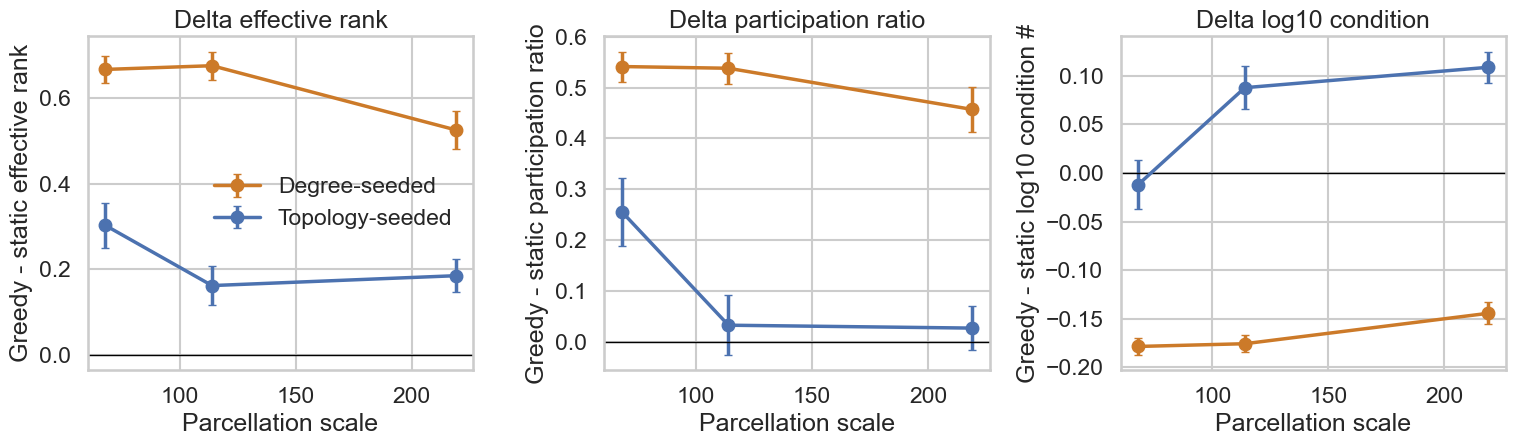

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8), sharex=True)
metric_specs = [
    ('mean_delta_effective_rank', 'sem_delta_effective_rank', 'Delta effective rank', 'Greedy - static effective rank'),
    ('mean_delta_participation_ratio', 'sem_delta_participation_ratio', 'Delta participation ratio', 'Greedy - static participation ratio'),
    ('mean_delta_log10_condition_number', 'sem_delta_log10_condition_number', 'Delta log10 condition', 'Greedy - static log10 condition #'),
]

for ax, (mean_col, sem_col, title, ylabel) in zip(axes, metric_specs):
    for method in methods:
        subset = (
            geometry_summary[geometry_summary['method'] == method]
            .groupby('scale', as_index=False)[[mean_col, sem_col]]
            .mean()
            .sort_values('scale')
        )
        ax.errorbar(
            subset['scale'],
            subset[mean_col],
            yerr=subset[sem_col],
            marker='o',
            linewidth=2.5,
            capsize=3,
            color=palette[method],
            label=label_map[method],
        )
    ax.axhline(0, color='black', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Parcellation scale')
    ax.set_ylabel(ylabel)

axes[0].legend(frameon=False, title='')
fig.tight_layout()
out = FIGURES_DIR / 'static_vs_greedy_geometry_deltas.svg'
fig.savefig(out, bbox_inches='tight')
out


## Hard-direction overlap

The overlap table lets us compare whether greedy extension mainly preserves or rotates the hardest controllability directions. We focus on four interpretable pairs:

- degree static vs degree greedy,
- topology static vs topology greedy,
- degree static vs topology static,
- degree greedy vs topology greedy.


In [13]:
pairs = [
    ('degree_strength', 'static', 'degree_strength', 'greedy', 'Degree static vs degree greedy'),
    ('cycle_participation', 'static', 'cycle_participation', 'greedy', 'Topology static vs topology greedy'),
    ('degree_strength', 'static', 'cycle_participation', 'static', 'Degree static vs topology static'),
    ('degree_strength', 'greedy', 'cycle_participation', 'greedy', 'Degree greedy vs topology greedy'),
]

rows = []
for method_a, strategy_a, method_b, strategy_b, label in pairs:
    subset = overlap[
        (overlap['method_a'] == method_a)
        & (overlap['strategy_a'] == strategy_a)
        & (overlap['method_b'] == method_b)
        & (overlap['strategy_b'] == strategy_b)
    ].copy()
    subset['pair_label'] = label
    rows.append(subset)

overlap_focus = pd.concat(rows, ignore_index=True)
overlap_summary = (
    overlap_focus.groupby(['pair_label', 'scale'], as_index=False)
    .agg(
        mean_overlap=('overlap', 'mean'),
        sem_overlap=('overlap', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    )
)
overlap_summary


,pair_label,scale,mean_overlap,sem_overlap
0,Degree greedy vs topology greedy,68,0.448920,0.007208
1,Degree greedy vs topology greedy,114,0.433764,0.007728
2,Degree greedy vs topology greedy,219,0.411081,0.006643
3,Degree static vs degree greedy,68,0.595706,0.014676
4,Degree static vs degree greedy,114,0.588902,0.014850
5,Degree static vs degree greedy,219,0.584891,0.015335
6,Degree static vs topology static,68,0.439860,0.006893
7,Degree static vs topology static,114,0.431372,0.007468
8,Degree static vs topology static,219,0.408564,0.006271
9,Topology static vs topology greedy,68,0.593147,0.015075


PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_static_vs_greedy/static_vs_greedy_eigenspace_overlap.svg')

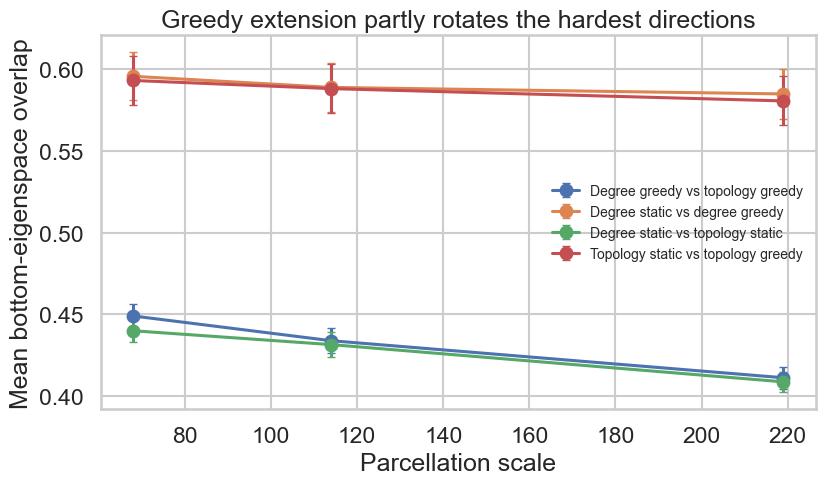

In [14]:
fig, ax = plt.subplots(figsize=(8.6, 5.2))
for pair_label, subset in overlap_summary.groupby('pair_label'):
    subset = subset.sort_values('scale')
    ax.errorbar(
        subset['scale'],
        subset['mean_overlap'],
        yerr=subset['sem_overlap'],
        marker='o',
        linewidth=2.2,
        capsize=3,
        label=pair_label,
    )
ax.set_xlabel('Parcellation scale')
ax.set_ylabel('Mean bottom-eigenspace overlap')
ax.set_title('Greedy extension partly rotates the hardest directions')
ax.legend(frameon=False, fontsize=10, title='')
fig.tight_layout()
out = FIGURES_DIR / 'static_vs_greedy_eigenspace_overlap.svg'
fig.savefig(out, bbox_inches='tight')
out


## Notes for interpretation


In [15]:

print('Scalar energy: mean greedy-minus-static log10 energy by scale and method')
print(scalar_tests[['scale', 'method', 'mean_greedy_minus_static', 'p_value_holm', 'reject_holm']].to_string(index=False))

print('\nGeometry: mean greedy-minus-static deltas by scale and method')
print(geometry_tests_zero[['metric', 'scale', 'method', 'mean_delta', 'p_value_holm_local', 'reject_holm_local']].to_string(index=False))

print('\nCycle minus degree difference in geometry deltas (subject-averaged over k)')
print(geometry_cycle_vs_degree[['metric', 'scale', 'cycle_minus_degree_mean', 'p_value_holm_local', 'reject_holm_local']].to_string(index=False))

print('\nHard-direction overlap summary')
print(overlap_summary.to_string(index=False))


Scalar energy: mean greedy-minus-static log10 energy by scale and method
 scale              method  mean_greedy_minus_static  p_value_holm  reject_holm
    68 cycle_participation                 -0.004405  3.068545e-35         True
    68     degree_strength                 -0.005111  2.404371e-35         True
   114 cycle_participation                 -0.002420  3.068545e-35         True
   114     degree_strength                 -0.002171  2.404371e-35         True
   219 cycle_participation                 -0.001456  1.978336e-35         True
   219     degree_strength                 -0.000953  3.068545e-35         True

Geometry: mean greedy-minus-static deltas by scale and method
                      metric  scale              method  mean_delta  p_value_holm_local  reject_holm_local
        delta_effective_rank     68 cycle_participation    0.302553        5.037354e-18               True
        delta_effective_rank     68     degree_strength    0.666752        6.220588e-34   